
--- Learning rate 0.1 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final params: tensor([nan, nan, nan])

--- Learning rate 0.01 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final params: tensor([nan, nan, nan])

--- Learning rate 0.001 ---
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final params: tensor([nan, nan, nan])

--- Learning rate 0.0001 ---
Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171005
Epoch 2000, Loss 6.123478
Epoch 2500, Loss 5.377227
Epoch 3000, Los

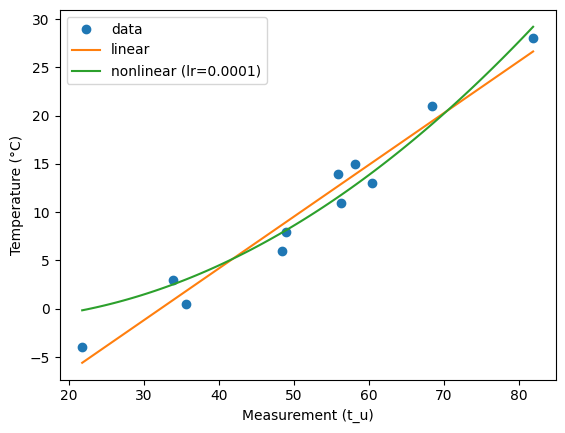

In [ ]:
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

t_c = torch.tensor([0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0])
t_u = torch.tensor([35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4])
t_un = 0.1 * t_u

def model_linear(t_u, w, b):
    return w * t_u + b



def loss_fn(t_p, t_c):
    return ((t_p - t_c)**2).mean()

def model_nonlinear(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b

def training_loop(n_epochs, optimizer, params, model, t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss {loss.item():.6f}")
    return params, loss.item()

results = {}
for lr in [1e-1, 1e-2, 1e-3, 1e-4]:
    print(f"\nLearning rate {lr}")
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)
    optimizer = optim.SGD([params], lr=lr)
    params, final_loss = training_loop(5000, optimizer, params, model_nonlinear, t_un, t_c)
    results[lr] = (params.detach().clone(), final_loss)
    print("Final params:", params.detach())



lin_params = torch.tensor([1.0, 0.0], requires_grad=True)
lin_params, lin_loss = training_loop(5000, optim.SGD([lin_params], lr=1e-2),
                                     lin_params, model_linear, t_un, t_c)
import math
best_lr = min((lr for lr in results if math.isfinite(results[lr][1])),
              key=lambda lr: results[lr][1])
best_params, best_loss = results[best_lr]
print(f"Linear loss: {lin_loss:.4f} | Best nonlinear (lr={best_lr}) loss: {best_loss:.4f}")


x = torch.linspace(t_un.min(), t_un.max(), 100)
plt.plot(t_u, t_c, 'o', label='data')
plt.plot(x*10, model_linear(x, *lin_params).detach(), label='linear')
plt.plot(x*10, model_nonlinear(x, *best_params).detach(), label=f'nonlinear (lr={best_lr})')
plt.xlabel("Measurement (t_u)"); plt.ylabel("Temperature (°C)"); plt.legend(); plt.show()